## Import Libraries & Read Dataset

In [2]:
import pandas as pd
# import matlpotlib.pyplot as plt

df = pd.read_csv("StockMarketing.csv")
print(df)

           Date              Company       Ticker Country Currency     Open  \
0    05-01-2026  Reliance Industries  RELIANCE.NS   India      INR  1244.38   
1    06-01-2026  Reliance Industries  RELIANCE.NS   India      INR  1237.51   
2    07-01-2026  Reliance Industries  RELIANCE.NS   India      INR  1239.36   
3    08-01-2026  Reliance Industries  RELIANCE.NS   India      INR  1238.11   
4    09-01-2026  Reliance Industries  RELIANCE.NS   India      INR      NaN   
..          ...                  ...          ...     ...      ...      ...   
595  23-03-2026             Alphabet        GOOGL     USA      USD   168.67   
596  24-03-2026             Alphabet        GOOGL     USA      USD   169.26   
597  25-03-2026             Alphabet        GOOGL     USA      USD   169.43   
598  26-03-2026             Alphabet        GOOGL     USA      USD   169.17   
599  27-03-2026             Alphabet        GOOGL     USA      USD   170.11   

        High      Low    Close    Volume  
0    125

## Data Overview

In [3]:
print(df.shape)
print(df.columns)
df.info()
print(df.head(5))
print(df.describe())

(600, 10)
Index(['Date', 'Company', 'Ticker', 'Country', 'Currency', 'Open', 'High',
       'Low', 'Close', 'Volume'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      600 non-null    object 
 1   Company   600 non-null    object 
 2   Ticker    600 non-null    object 
 3   Country   600 non-null    object 
 4   Currency  600 non-null    object 
 5   Open      580 non-null    float64
 6   High      580 non-null    float64
 7   Low       590 non-null    float64
 8   Close     580 non-null    float64
 9   Volume    570 non-null    float64
dtypes: float64(5), object(5)
memory usage: 47.0+ KB
         Date              Company       Ticker Country Currency     Open  \
0  05-01-2026  Reliance Industries  RELIANCE.NS   India      INR  1244.38   
1  06-01-2026  Reliance Industries  RELIANCE.NS   India      INR  1237.51   
2 

# Data Quality and Exploration

In [4]:
print(df.isnull().sum())
print(df.duplicated().sum())

Date         0
Company      0
Ticker       0
Country      0
Currency     0
Open        20
High        20
Low         10
Close       20
Volume      30
dtype: int64
0


In [5]:
missing_data = df[df.isnull().any(axis=1)]
# df.head(10)
print("Total rows with missing values:", len(missing_data))
missing_data.head(10)

Total rows with missing values: 100


,Date,Company,Ticker,Country,Currency,Open,High,Low,Close,Volume
4,09-01-2026,Reliance Industries,RELIANCE.NS,India,INR,NaN,1241.16,1226.35,1233.76,119800.0
6,13-01-2026,Reliance Industries,RELIANCE.NS,India,INR,1239.29,1249.20,1230.00,1236.18,NaN
8,15-01-2026,Reliance Industries,RELIANCE.NS,India,INR,1244.23,NaN,1235.52,1249.80,117200.0
13,22-01-2026,Reliance Industries,RELIANCE.NS,India,INR,1243.51,1255.96,NaN,1247.23,141950.0
17,28-01-2026,Reliance Industries,RELIANCE.NS,India,INR,1248.41,1257.15,1237.18,NaN,139350.0
21,03-02-2026,Reliance Industries,RELIANCE.NS,India,INR,NaN,1250.79,1232.81,1242.10,136750.0
27,11-02-2026,Reliance Industries,RELIANCE.NS,India,INR,1243.87,1260.69,1237.65,1249.45,NaN
32,18-02-2026,Reliance Industries,RELIANCE.NS,India,INR,1243.15,NaN,1234.45,1246.87,168800.0
43,05-03-2026,Reliance Industries,RELIANCE.NS,India,INR,1237.37,1252.86,1229.95,NaN,178450.0
51,17-03-2026,Reliance Industries,RELIANCE.NS,India,INR,1242.80,1257.73,1236.58,1246.51,NaN


In [6]:
df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(df_clean["Date"], dayfirst=True)

df_clean = df_clean.sort_values(["Company", "Date"]).reset_index(drop=True)

In [7]:
print(df.shape)
print(df_clean.shape)
print(df_clean["Date"].head()) 

(600, 10)
(600, 10)
0   2026-01-05
1   2026-01-06
2   2026-01-07
3   2026-01-08
4   2026-01-09
Name: Date, dtype: datetime64[ns]


In [8]:
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100
print(missing_percentage) 

Date        0.000000
Company     0.000000
Ticker      0.000000
Country     0.000000
Currency    0.000000
Open        3.333333
High        3.333333
Low         1.666667
Close       3.333333
Volume      5.000000
dtype: float64


In [9]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

Total Missing Values: 100


In [10]:
df_clean.groupby("Company")["Close"].count() 

Company
Alphabet                     58
Amazon                       58
Apple                        58
HDFC Bank                    58
ICICI Bank                   58
Infosys                      58
Microsoft                    58
NVIDIA                       58
Reliance Industries          58
Tata Consultancy Services    58
Name: Close, dtype: int64

In [11]:
df_clean.dropna(subset=["Open", "High", "Low", "Close"]).shape 

(530, 10)

In [12]:
complete_data = df_clean.dropna(subset=["Open", "High", "Low", "Close"])
print(round(len(complete_data) / len(df_clean) * 100, 2), "%")

88.33 %


In [13]:
df_price = df_clean.dropna(subset=["Open", "High", "Low", "Close"]).copy()
print(df_price.shape)

(530, 10)


In [14]:
df_price[(df_price["High"] < df_price["Open"]) |
    (df_price["High"] < df_price["Close"])]

,Date,Company,Ticker,Country,Currency,Open,High,Low,Close,Volume


In [15]:
df_price[
    (df_price["Low"] > df_price["Open"]) |
    (df_price["Low"] > df_price["Close"])
    ] 

,Date,Company,Ticker,Country,Currency,Open,High,Low,Close,Volume


In [16]:
print(df_price.shape)

(530, 10)


In [17]:
df_price = df_price.sort_values(by=["Company", "Date"]).reset_index(drop=True)
df_price["Daily_Return"] = (df_price.groupby("Company")["Close"].pct_change() * 100)
df_price[["Date", "Company", "Close", "Daily_Return"]].head(10)

,Date,Company,Close,Daily_Return
0,2026-01-05,Alphabet,169.15,NaN
1,2026-01-06,Alphabet,169.49,0.201005
2,2026-01-07,Alphabet,171.01,0.896808
3,2026-01-08,Alphabet,170.50,-0.298228
4,2026-01-12,Alphabet,169.81,-0.404692
5,2026-01-13,Alphabet,169.64,-0.100112
6,2026-01-14,Alphabet,170.66,0.601273
7,2026-01-16,Alphabet,169.81,-0.498066
8,2026-01-19,Alphabet,171.17,0.800895
9,2026-01-20,Alphabet,170.48,-0.403108


In [18]:
company_returns = df_price.groupby("Company")["Daily_Return"].mean()
company_returns = company_returns.sort_values(ascending=False)
print(company_returns)

Company
Alphabet                     0.021140
Infosys                      0.017119
Tata Consultancy Services    0.011428
NVIDIA                       0.009341
Reliance Industries          0.005418
Microsoft                    0.003605
Apple                       -0.002287
ICICI Bank                  -0.007742
HDFC Bank                   -0.013448
Amazon                      -0.021269
Name: Daily_Return, dtype: float64


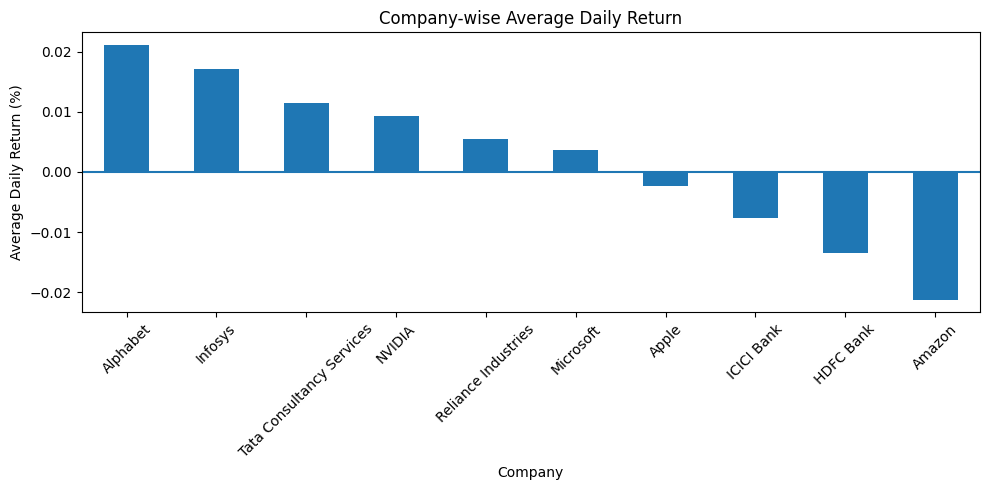

In [19]:
import matplotlib.pyplot as plt

company_returns.plot(kind="bar", figsize=(10, 5))
plt.title("Company-wise Average Daily Return")
plt.xlabel("Company")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=45)
plt.axhline(y=0)
plt.tight_layout()
plt.show()

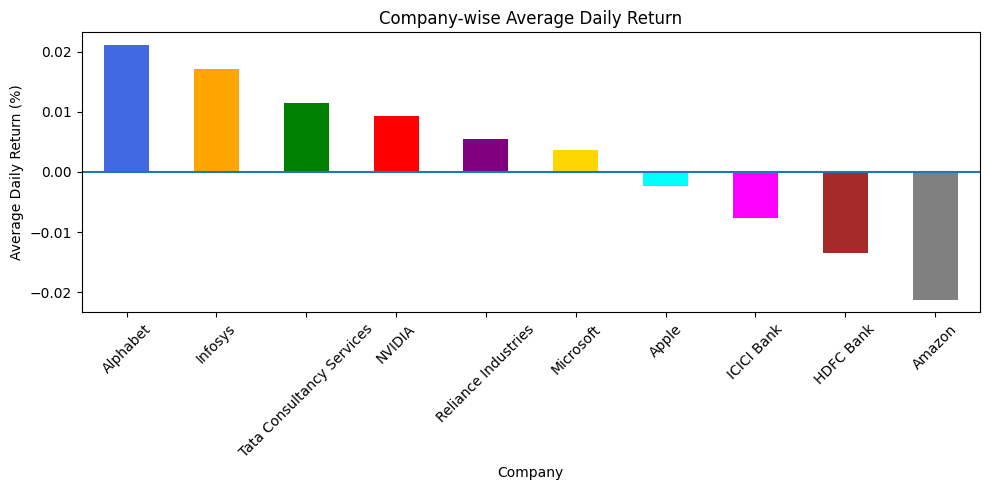

In [20]:
company_returns.plot(kind="bar", figsize=(10, 5), 
color=["royalblue", "orange", "green", "red", "purple",
    "gold", "cyan", "magenta", "brown", "gray"])

plt.title("Company-wise Average Daily Return")
plt.xlabel("Company")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=45)
plt.axhline(y=0)
plt.tight_layout()
plt.show()

In [21]:
company_performance = df_price.groupby("Company")["Close"].agg(["first", "last"])

print(company_performance)
company_performance["Total_Return"] = (
    (company_performance["last"] - company_performance["first"])
    / company_performance["first"]
) * 100

print(company_performance)

                             first     last
Company                                    
Alphabet                    169.15   170.87
Amazon                      180.54   178.40
Apple                       191.52   191.16
HDFC Bank                  1658.25  1645.23
ICICI Bank                 1046.85  1041.74
Infosys                    1491.00  1503.15
Microsoft                   410.00   410.45
NVIDIA                      119.04   119.53
Reliance Industries        1238.75  1241.39
Tata Consultancy Services  3507.00  3524.93
                             first     last  Total_Return
Company                                                  
Alphabet                    169.15   170.87      1.016849
Amazon                      180.54   178.40     -1.185333
Apple                       191.52   191.16     -0.187970
HDFC Bank                  1658.25  1645.23     -0.785165
ICICI Bank                 1046.85  1041.74     -0.488131
Infosys                    1491.00  1503.15      0.814889
Microsof

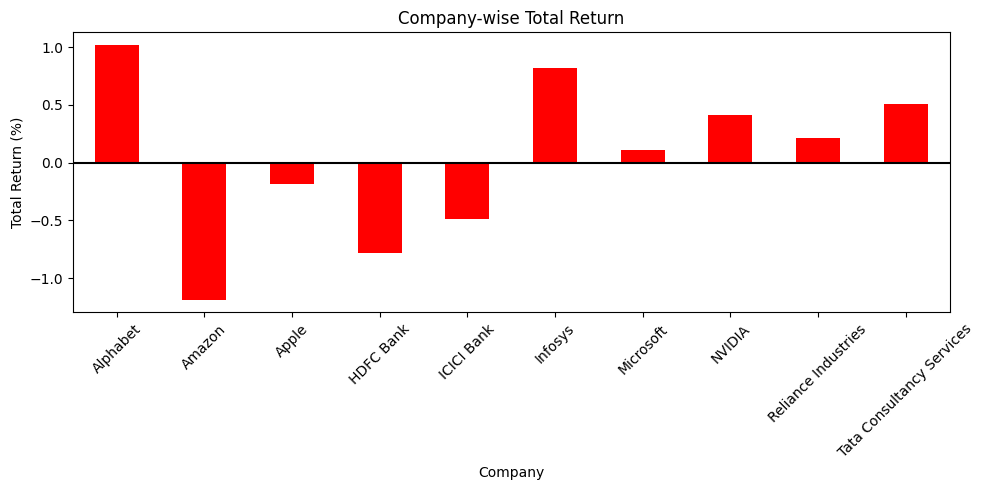

In [22]:
company_performance["Total_Return"].plot(kind="bar",figsize=(10, 5),color="red")

plt.title("Company-wise Total Return")
plt.xlabel("Company")
plt.ylabel("Total Return (%)") 
plt.xticks(rotation=45)
plt.axhline(y=0, color="black")
plt.tight_layout()
plt.show() 

Country
India    0.002555
USA      0.002106
Name: Daily_Return, dtype: float64


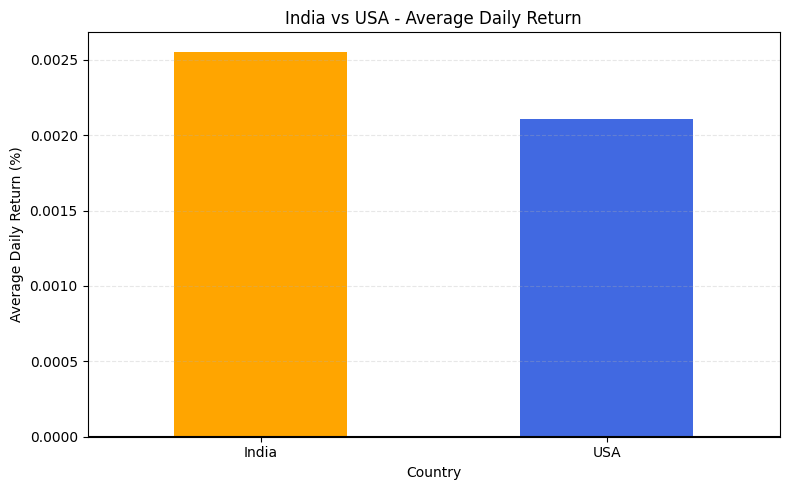

In [23]:
country_returns = df_price.groupby("Country")["Daily_Return"].mean()
print(country_returns)
country_returns.plot(kind="bar", figsize=(8, 5), color=["orange", "royalblue"])

plt.title("India vs USA - Average Daily Return")
plt.xlabel("Country")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=0)
plt.axhline(y=0, color="black")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show() 

Company
Alphabet                     13785200.0
Amazon                       13160200.0
NVIDIA                       12535200.0
Microsoft                    11910200.0
Apple                        11285200.0
ICICI Bank                   10660200.0
HDFC Bank                    10035200.0
Infosys                       9410200.0
Tata Consultancy Services     8785200.0
Reliance Industries           8160200.0
Name: Volume, dtype: float64


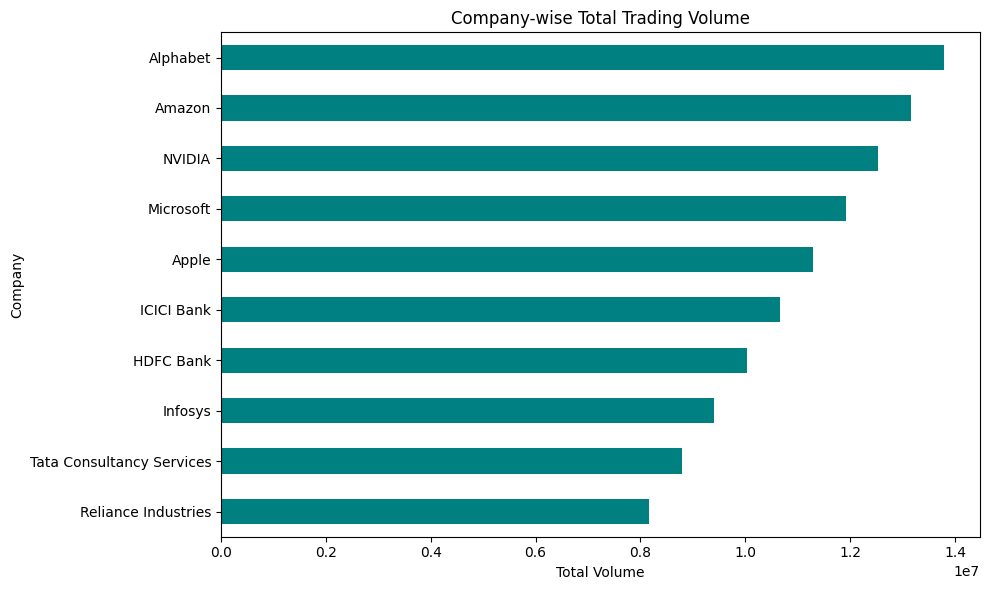

In [24]:
volume = df_price.groupby("Company")["Volume"].sum()
print(volume.sort_values(ascending=False))
volume.sort_values().plot(kind="barh",figsize=(10, 6),color="teal")

plt.title("Company-wise Total Trading Volume")
plt.xlabel("Total Volume")
plt.ylabel("Company")
plt.tight_layout()
plt.show()

Month    Company                  
2026-01  Alphabet                      169.975000
         Amazon                        179.558125
         Apple                         190.243750
         HDFC Bank                    1658.240000
         ICICI Bank                   1043.972500
         Infosys                      1493.326875
         Microsoft                     412.464375
         NVIDIA                        119.146250
         Reliance Industries          1241.626875
         Tata Consultancy Services    3517.924375
2026-02  Alphabet                      169.866111
         Amazon                        179.418889
         Apple                         189.997222
         HDFC Bank                    1657.611667
         ICICI Bank                   1044.130000
         Infosys                      1492.175556
         Microsoft                     412.741111
         NVIDIA                        119.067778
         Reliance Industries          1241.325556
         Tata C

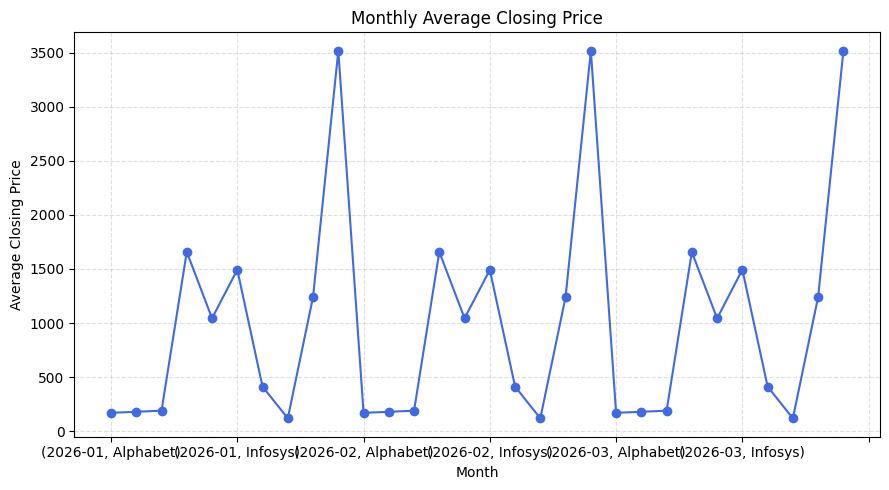

In [25]:
df_price["Month"] = df_price["Date"].dt.to_period("M")

monthly_price = (df_price.groupby(["Month", "Company"])["Close"].mean())
print(monthly_price)

monthly_price.plot(kind="line",figsize=(9, 5),marker="o",color="royalblue")
plt.title("Monthly Average Closing Price")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [26]:
monthly_company = df_price.groupby(["Month", "Company"])["Close"].mean()
print(monthly_company)

Month    Company                  
2026-01  Alphabet                      169.975000
         Amazon                        179.558125
         Apple                         190.243750
         HDFC Bank                    1658.240000
         ICICI Bank                   1043.972500
         Infosys                      1493.326875
         Microsoft                     412.464375
         NVIDIA                        119.146250
         Reliance Industries          1241.626875
         Tata Consultancy Services    3517.924375
2026-02  Alphabet                      169.866111
         Amazon                        179.418889
         Apple                         189.997222
         HDFC Bank                    1657.611667
         ICICI Bank                   1044.130000
         Infosys                      1492.175556
         Microsoft                     412.741111
         NVIDIA                        119.067778
         Reliance Industries          1241.325556
         Tata C

In [29]:
df_price.to_csv("Stock_Clean.csv", index=False)

In [303]:
# print(df.shape)
# print(df_clean.shape)
# print(df_clean["Date"].head()) 